Attention function implemented.
Test 1 passed: attention weights sum to 1.
Maximum difference: 2.384185791015625e-07
Test 2 passed: matches PyTorch.
Test 3 passed: future positions get zero attention; matches PyTorch causal.
Test 4 passed: batched multi-head causal attention.
Attention weights:
 tensor([[0.4223, 0.1554, 0.4223],
        [0.3333, 0.3333, 0.3333],
        [0.4223, 0.1554, 0.4223]])

Attention output:
 tensor([[20.],
        [20.],
        [20.]])

Hand calculation test passed.


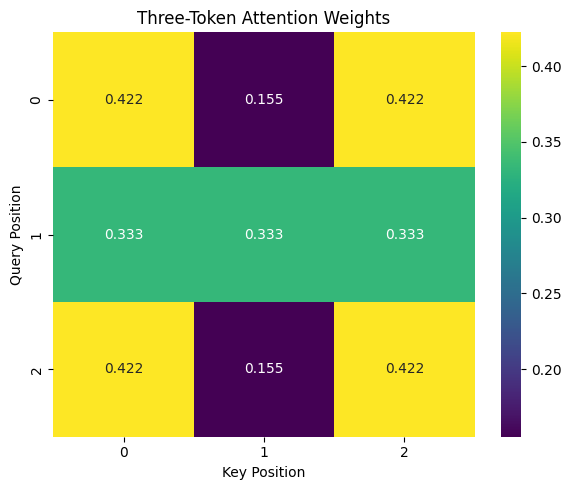

In [10]:
import os
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)

# ============================================================
# TASK 1: SCALED DOT-PRODUCT ATTENTION
# ============================================================

def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q: (B, H, Tq, d_k)
    K: (B, H, Tk, d_k)
    V: (B, H, Tk, d_v)
    mask: optional boolean tensor, broadcastable to (B, H, Tq, Tk).
          True = allowed, False = blocked.
    Note: a row that is fully masked gives NaN (softmax of all -inf).
          A causal mask never does, because the diagonal is allowed.

    Returns:
        output:  (B, H, Tq, d_v)
        weights: (B, H, Tq, Tk)
    """
    d_k = Q.size(-1)

    # (B, H, Tq, d_k) @ (B, H, d_k, Tk) -> (B, H, Tq, Tk)
    scores = torch.matmul(Q, K.transpose(-2, -1))

    # scale by sqrt(d_k); shape unchanged: (B, H, Tq, Tk)
    scores = scores / math.sqrt(d_k)

    if mask is not None:
        # blocked positions get -inf, so softmax gives them exactly 0
        scores = scores.masked_fill(~mask, float("-inf"))

    # softmax over the key axis: (B, H, Tq, Tk), each row sums to 1
    weights = torch.softmax(scores, dim=-1)

    # (B, H, Tq, Tk) @ (B, H, Tk, d_v) -> (B, H, Tq, d_v)
    output = torch.matmul(weights, V)

    return output, weights


print("Attention function implemented.")

# ============================================================
# TEST 1: ROWS SUM TO 1
# ============================================================
torch.manual_seed(42)
B, H, T, d_k = 2, 4, 8, 16
Q = torch.randn(B, H, T, d_k)
K = torch.randn(B, H, T, d_k)
V = torch.randn(B, H, T, d_k)

output, weights = scaled_dot_product_attention(Q, K, V)

assert output.shape == (B, H, T, d_k)
assert weights.shape == (B, H, T, T)
assert torch.allclose(weights.sum(dim=-1), torch.ones(B, H, T), atol=1e-6)
print("Test 1 passed: attention weights sum to 1.")

# ============================================================
# TEST 2: MATCHES torch.nn.functional.scaled_dot_product_attention
# ============================================================
reference = F.scaled_dot_product_attention(Q, K, V, dropout_p=0.0)
custom, _ = scaled_dot_product_attention(Q, K, V)

difference = torch.max(torch.abs(reference - custom)).item()
print("Maximum difference:", difference)
assert torch.allclose(reference, custom, atol=1e-5, rtol=1e-5)
print("Test 2 passed: matches PyTorch.")

# ============================================================
# TEST 3: CAUSAL MASK
# ============================================================
torch.manual_seed(42)               # reproducible regardless of earlier cells
T = 5
causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool))   # (T, T), broadcasts

Q = torch.randn(1, 1, T, 16)
K = torch.randn(1, 1, T, 16)
V = torch.randn(1, 1, T, 16)

output, weights = scaled_dot_product_attention(Q, K, V, mask=causal_mask)

for i in range(T):
    assert torch.all(weights[0, 0, i, i + 1:] == 0)            # future = exactly 0
assert torch.all(weights[0, 0].triu(1) == 0)                    # whole upper triangle is 0
assert torch.allclose(weights.sum(-1), torch.ones(1, 1, T), atol=1e-6)  # rows still sum to 1
assert torch.allclose(weights[0, 0, 0, 0], torch.tensor(1.0))   # token 0 attends only to itself

ref_causal = F.scaled_dot_product_attention(Q, K, V, is_causal=True)
assert torch.allclose(output, ref_causal, atol=1e-5, rtol=1e-5)  # matches library with mask
print("Test 3 passed: future positions get zero attention; matches PyTorch causal.")

# ============================================================
# TEST 4: BATCHED, MULTI-HEAD MASK (shape check before building MHA)
# ============================================================
torch.manual_seed(0)
B, H, T, d_k = 3, 4, 6, 8
Q = torch.randn(B, H, T, d_k); K = torch.randn(B, H, T, d_k); V = torch.randn(B, H, T, d_k)
m = torch.tril(torch.ones(T, T, dtype=torch.bool))
out, w = scaled_dot_product_attention(Q, K, V, mask=m)
assert out.shape == (B, H, T, d_k) and w.shape == (B, H, T, T)
assert torch.all(w.triu(1) == 0)
assert torch.allclose(out, F.scaled_dot_product_attention(Q, K, V, is_causal=True), atol=1e-5)
print("Test 4 passed: batched multi-head causal attention.")

# ============================================================
# THREE-TOKEN HAND-CHECKABLE EXAMPLE
# (State in the report whether this is the instructor's example or your own.)
# ============================================================
Q = torch.tensor([[[[1.0], [0.0], [1.0]]]])     # (1, 1, 3, 1)
K = torch.tensor([[[[1.0], [0.0], [1.0]]]])
V = torch.tensor([[[[10.0], [20.0], [30.0]]]])

output, weights = scaled_dot_product_attention(Q, K, V)

print("Attention weights:\n", weights[0, 0])
print("\nAttention output:\n", output[0, 0])

# Hand calculation (d_k = 1, so scaling by sqrt(1) = 1):
#   scores row 1 = [1, 0, 1] -> softmax = [e, 1, e] / (2e + 1) = [0.4223, 0.1554, 0.4223]
#   scores row 2 = [0, 0, 0] -> softmax = [1/3, 1/3, 1/3]
#   output row 1 = 0.4223*10 + 0.1554*20 + 0.4223*30 = 20
#   output row 2 = (10 + 20 + 30) / 3 = 20
expected_weights = torch.softmax(
    torch.tensor([[1.0, 0.0, 1.0],
                  [0.0, 0.0, 0.0],
                  [1.0, 0.0, 1.0]]), dim=-1)
expected_output = expected_weights @ V[0, 0]

assert torch.allclose(weights[0, 0], expected_weights, atol=1e-6)
assert torch.allclose(output[0, 0], expected_output, atol=1e-6)
assert torch.allclose(output[0, 0], torch.full((3, 1), 20.0), atol=1e-5)  # hand-computed value
print("\nHand calculation test passed.")

# ============================================================
# FIGURE
# ============================================================
plt.figure(figsize=(6, 5))
sns.heatmap(weights[0, 0].detach().numpy(), annot=True, cmap="viridis", fmt=".3f")
plt.title("Three-Token Attention Weights")
plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.tight_layout()
plt.savefig("figures/task1_attention_example.png", dpi=300)
plt.show()

In [ ]:

# ============================================================
# PROBLEM 2 - TASK 2: MULTI-HEAD ATTENTION + PRE-LN ENCODER
# ============================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# 1. MULTI-HEAD ATTENTION
# ============================================================

class MultiHeadAttention(nn.Module):

    def __init__(self, d, h, dropout=0.0):

        super().__init__()

        assert d % h == 0, "d must be divisible by h"

        self.d = d
        self.h = h
        self.head_dim = d // h

        self.W_Q = nn.Linear(d, d)
        self.W_K = nn.Linear(d, d)
        self.W_V = nn.Linear(d, d)
        self.W_O = nn.Linear(d, d)

        self.dropout = dropout

    def attention(self, Q, K, V, causal_mask=None):

        # Q, K, V: (B, H, T, head_dim)

        scores = torch.matmul(
            Q,
            K.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        # Apply causal mask
        # True = allowed, False = blocked

        if causal_mask is not None:

            scores = scores.masked_fill(
                causal_mask == 0,
                float("-inf")
            )

        weights = torch.softmax(
            scores,
            dim=-1
        )

        weights = F.dropout(
            weights,
            p=self.dropout,
            training=self.training
        )

        out = torch.matmul(weights, V)

        return out, weights

    def forward(self, x, causal_mask=None):

        B, T, d = x.shape

        # Linear projections

        Q = self.W_Q(x)
        K = self.W_K(x)
        V = self.W_V(x)

        # Split into multiple attention heads

        Q = Q.view(
            B, T, self.h, self.head_dim
        ).transpose(1, 2)

        K = K.view(
            B, T, self.h, self.head_dim
        ).transpose(1, 2)

        V = V.view(
            B, T, self.h, self.head_dim
        ).transpose(1, 2)

        # Scaled dot-product attention

        out, weights = self.attention(
            Q, K, V, causal_mask
        )

        # Merge attention heads

        out = out.transpose(
            1, 2
        ).contiguous().view(B, T, d)

        return self.W_O(out), weights


# ============================================================
# 2. SINUSOIDAL POSITIONAL ENCODING
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):

    def __init__(self, d, max_len=5000):

        super().__init__()

        assert d % 2 == 0, "d must be even"

        position = torch.arange(
            max_len,
            dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d)
        )

        pe = torch.zeros(max_len, d)

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term
        )

        self.register_buffer(
            "pe",
            pe.unsqueeze(0)
        )

    def forward(self, x):

        return x + self.pe[:, :x.size(1), :]


# ============================================================
# 3. PRE-LN TRANSFORMER ENCODER BLOCK
# ============================================================

class EncoderBlock(nn.Module):

    def __init__(self, d, h, dropout=0.1):

        super().__init__()

        self.ln1 = nn.LayerNorm(d)
        self.ln2 = nn.LayerNorm(d)

        self.mha = MultiHeadAttention(
            d, h, dropout
        )

        self.ffn = nn.Sequential(
            nn.Linear(d, 4 * d),
            nn.GELU(),
            nn.Linear(4 * d, d)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, causal_mask=None):

        # Pre-LN multi-head attention + residual

        x = x + self.dropout(
            self.mha(
                self.ln1(x),
                causal_mask
            )[0]
        )

        # Pre-LN feed-forward network + residual

        x = x + self.dropout(
            self.ffn(self.ln2(x))
        )

        return x


# ============================================================
# 4. TEST 1: PARAMETER COUNT
# ============================================================

def test_parameter_count():

    d, h = 128, 8

    d_ff = 4 * d

    model = EncoderBlock(
        d, h, dropout=0.0
    )

    total = sum(
        p.numel()
        for p in model.parameters()
    )

    weights = 4 * d * d + 2 * d * d_ff
    attn_bias = 4 * d
    ffn_bias = d_ff + d
    layernorm = 2 * (2 * d)

    assert weights == 196608

    assert total == (
        weights + attn_bias + ffn_bias + layernorm
    ) == 198272

    print(
        "Parameter count:",
        total,
        "= 196,608 + 512 + 640 + 512"
    )


test_parameter_count()


# ============================================================
# 5. TEST 2: OUTPUT SHAPES
# ============================================================

def test_shapes():

    B, T, d, h = 4, 20, 128, 8

    model = EncoderBlock(d, h).eval()

    x = torch.randn(B, T, d)

    output = model(x)

    assert output.shape == (B, T, d)

    print("Shape test passed.")


test_shapes()


# ============================================================
# 6. TEST 3: MATCH PYTORCH REFERENCE ATTENTION
# ============================================================

def test_mha_matches_reference():

    torch.manual_seed(0)

    d, h, B, T = 128, 8, 2, 10

    mha = MultiHeadAttention(
        d, h, dropout=0.0
    ).eval()

    x = torch.randn(B, T, d)

    mask = torch.tril(
        torch.ones(T, T)
    ).bool()

    hd = d // h

    q, k, v = [
        lin(x).view(
            B, T, h, hd
        ).transpose(1, 2)
        for lin in (
            mha.W_Q,
            mha.W_K,
            mha.W_V
        )
    ]

    for m, causal in (
        (None, False),
        (mask, True)
    ):

        out, _ = mha(x, m)

        ref = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=causal
        )

        ref = mha.W_O(
            ref.transpose(
                1, 2
            ).reshape(B, T, d)
        )

        assert torch.allclose(
            out,
            ref,
            atol=1e-5,
            rtol=1e-5
        )

    print(
        "MHA matches library attention "
        "(with and without causal mask)."
    )


test_mha_matches_reference()


# ============================================================
# 7. TEST 4: POSITIONAL ENCODING
# ============================================================

def test_positional_encoding():

    pe = SinusoidalPositionalEncoding(
        128, 64
    ).pe[0]

    assert pe.shape == (64, 128)

    assert torch.allclose(
        pe[0, 0::2],
        torch.zeros(64),
        atol=1e-6
    )

    assert torch.allclose(
        pe[0, 1::2],
        torch.ones(64),
        atol=1e-6
    )

    assert len(
        list(
            SinusoidalPositionalEncoding(128).parameters()
        )
    ) == 0

    print("Positional encoding test passed.")


test_positional_encoding()


# ============================================================
# 8. TEST 5: CAUSAL MASK
# ============================================================

def test_causal_mask():

    torch.manual_seed(0)

    B, T, d, h = 2, 8, 128, 8

    model = EncoderBlock(
        d, h, dropout=0.0
    ).eval()

    x = torch.randn(B, T, d)

    mask = torch.tril(
        torch.ones(T, T)
    ).bool()

    _, w = model.mha(
        model.ln1(x),
        mask
    )

    # Future attention weights must be zero

    assert torch.all(
        w.triu(1) == 0
    )

    # Attention rows must sum to one

    assert torch.allclose(
        w.sum(-1),
        torch.ones(B, h, T),
        atol=1e-6
    )

    # Changing the final token must not affect
    # earlier outputs when causal masking is used

    x2 = x.clone()

    x2[:, -1] += 5.0

    assert torch.allclose(
        model(x, mask)[:, :-1],
        model(x2, mask)[:, :-1],
        atol=1e-5
    )

    print("Causal mask test passed.")


test_causal_mask()


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 60)

print("ALL TRANSFORMER BLOCK TESTS PASSED!")

print("=" * 60)


Parameter count: 198272 = 196,608 + 512 + 640 + 512
Shape test passed.
MHA matches library attention (with and without causal mask).
Positional encoding test passed.
Causal mask test passed.

ALL TRANSFORMER BLOCK TESTS PASSED!


In [ ]:
# ===== HAR data for Problem 2 (same pipeline as Problem 1) =====
import os, urllib.request, zipfile
from pathlib import Path
import numpy as np

dataset_root = Path("har/UCI HAR Dataset")
if not dataset_root.exists():
    os.makedirs("har", exist_ok=True)
    url = ("https://archive.ics.uci.edu/static/public/240/"
           "human+activity+recognition+using+smartphones.zip")
    urllib.request.urlretrieve(url, "har.zip")
    with zipfile.ZipFile("har.zip") as z: z.extractall("har")
    nested = Path("har/UCI HAR Dataset.zip")          # archive may hold a second zip
    if nested.exists():
        with zipfile.ZipFile(nested) as z: z.extractall("har")
assert dataset_root.exists(), "UCI HAR dataset not found!"

CHANNELS = ["body_acc_x","body_acc_y","body_acc_z","body_gyro_x","body_gyro_y","body_gyro_z",
            "total_acc_x","total_acc_y","total_acc_z"]

def load_har_split(split):
    sig = dataset_root / split / "Inertial Signals"
    X = np.stack([np.loadtxt(sig / f"{c}_{split}.txt", dtype=np.float32) for c in CHANNELS], axis=-1)  # (N,128,9)
    y = np.loadtxt(dataset_root / split / f"y_{split}.txt", dtype=np.int64) - 1                         # 0-5
    s = np.loadtxt(dataset_root / split / f"subject_{split}.txt", dtype=np.int64)
    return X, y, s

X_full_train, y_full_train, train_subjects = load_har_split("train")
X_test_raw, y_test, test_subjects = load_har_split("test")
assert X_full_train.shape == (7352, 128, 9) and X_test_raw.shape == (2947, 128, 9)

def create_har_split(seed):
    rng = np.random.default_rng(seed)
    val_subj = rng.choice(np.unique(train_subjects), size=4, replace=False)
    val_mask = np.isin(train_subjects, val_subj)
    Xtr, ytr = X_full_train[~val_mask], y_full_train[~val_mask]
    Xva, yva = X_full_train[val_mask], y_full_train[val_mask]
    mean, std = Xtr.mean(axis=(0, 1)), Xtr.std(axis=(0, 1))      # training-only statistics
    std = np.where(std < 1e-8, 1.0, std)
    f = lambda a: ((a - mean) / std).astype(np.float32)
    return f(Xtr), ytr, f(Xva), yva, f(X_test_raw), y_test, mean, std, val_subj

out = create_har_split(0)
print("train", out[0].shape, "val", out[2].shape, "test", out[4].shape, "val subjects", out[-1])
assert np.allclose(out[0].mean(axis=(0, 1)), 0, atol=1e-3)
print("create_har_split defined: HAR DATA READY")

# ===== Problem 2, Task A: HAR encoder classifier + positional ablation (final) =====
import os, time, copy, random
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score

# Fail early if earlier cells have not been run
for name in ("EncoderBlock", "SinusoidalPositionalEncoding", "create_har_split"):
    assert name in globals(), f"Run the cell that defines {name} first."

# Same budget as Problem 1 Task 3 (state these in the report)
EPOCHS, BATCH, LR = 20, 64, 1e-3
HAR_SEEDS = (0, 1, 2)                       # use your variant's seeds if given
D, LAYERS, HEADS, DROPOUT = 128, 4, 8, 0.1  # assumptions: state in report
RESULTS_CSV = "../results.csv"              # use "results.csv" if you run one notebook from the zip root
COLS = ["problem","model","seed","seq_len","test_acc","macro_f1","test_mse",
        "params","sec_per_epoch","val_loss_nats","bits_per_char","notes"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True)


class HAREncoderClassifier(nn.Module):
    def __init__(self, d=128, num_layers=4, heads=8, dropout=0.1, num_classes=6,
                 positional="none", patch_size=8, input_channels=9):
        super().__init__()
        assert positional in ["none", "sinusoidal", "learned"]
        self.d, self.patch_size, self.positional = d, patch_size, positional
        patch_dim = patch_size * input_channels                  # 8 steps x 9 channels = 72
        self.patch_embedding = nn.Linear(patch_dim, d)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.num_patches = 128 // patch_size                     # 16
        self.sequence_length = self.num_patches + 1              # 17 with CLS
        if positional == "sinusoidal":
            self.pos_encoding = SinusoidalPositionalEncoding(d=d, max_len=self.sequence_length)
        elif positional == "learned":
            self.pos_encoding = nn.Parameter(torch.zeros(1, self.sequence_length, d))
            nn.init.trunc_normal_(self.pos_encoding, std=0.02)
        else:
            self.pos_encoding = None
        self.encoder = nn.ModuleList([EncoderBlock(d, heads, dropout) for _ in range(num_layers)])
        self.final_norm = nn.LayerNorm(d)
        self.classifier = nn.Linear(d, num_classes)

    def forward(self, x):                                        # x: (B, 128, 9)
        B, T, C = x.shape
        assert T == 128 and C == 9
        x = x.reshape(B, T // self.patch_size, self.patch_size, C)   # (B, 16, 8, 9)
        x = x.reshape(B, self.num_patches, -1)                       # (B, 16, 72)
        x = self.patch_embedding(x)                                  # (B, 16, d)
        x = torch.cat([self.cls_token.expand(B, -1, -1), x], dim=1)  # (B, 17, d)
        if self.positional == "sinusoidal":
            x = self.pos_encoding(x)
        elif self.positional == "learned":
            x = x + self.pos_encoding
        for block in self.encoder:                                   # no mask: bidirectional
            x = block(x, causal_mask=None)
        x = self.final_norm(x)
        return self.classifier(x[:, 0, :])                           # CLS -> (B, 6)


def test_har_models():
    x = torch.randn(4, 128, 9)
    counts = {}
    for pos in ("none", "sinusoidal", "learned"):
        m = HAREncoderClassifier(d=D, num_layers=LAYERS, heads=HEADS, positional=pos).eval()
        assert m(x).shape == (4, 6)
        counts[pos] = sum(p.numel() for p in m.parameters())
    assert counts["none"] == counts["sinusoidal"]                    # buffer adds no parameters
    assert counts["learned"] == counts["none"] + 17 * D              # learned table adds 17*d
    print("Model shape tests passed. Parameters:", counts)
test_har_models()


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def log_row(**kw):
    row = {c: kw.get(c, "") for c in COLS}
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", index=False,
                               header=not os.path.exists(RESULTS_CSV))

def make_loader(X, y, shuffle):
    return DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                      batch_size=BATCH, shuffle=shuffle)

@torch.no_grad()
def evaluate_har(model, loader, loss_fn):
    model.eval()
    total, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total += loss_fn(logits, y).item() * len(y)
        preds.append(logits.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return total / len(labels), float((preds == labels).mean()), float(f1_score(labels, preds, average="macro"))

def train_har_model(model, tr, va, te, epochs):
    model = model.to(DEVICE)
    opt, loss_fn = torch.optim.Adam(model.parameters(), lr=LR), nn.CrossEntropyLoss()
    best_val, best_state, times = float("inf"), None, []
    for ep in range(epochs):
        model.train()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for x, y in tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(); loss_fn(model(x), y).backward(); opt.step()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)                 # training time only, as in Task 3
        val_loss, _, _ = evaluate_har(model, va, loss_fn)
        if val_loss < best_val:                                # same criterion as Task 3
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    _, acc, f1 = evaluate_har(model, te, loss_fn)
    return dict(acc=acc, f1=f1, params=sum(p.numel() for p in model.parameters()),
                spe=float(np.mean(times)), best_val=best_val)

# remove earlier P2_HAR rows so re-runs do not duplicate
if os.path.exists(RESULTS_CSV):
    old = pd.read_csv(RESULTS_CSV)
    old[old.problem != "P2_HAR"].to_csv(RESULTS_CSV, index=False)

# ----- 3 positional options x 3 seeds -----
for seed in HAR_SEEDS:
    Xtr, ytr, Xva, yva, Xte, yte, *_ = create_har_split(seed)   # same split as Problem 1
    tr = make_loader(Xtr, ytr, True)
    va = make_loader(Xva, yva, False)
    te = make_loader(Xte, yte, False)
    for pos in ("none", "sinusoidal", "learned"):
        set_seed(seed)
        model = HAREncoderClassifier(d=D, num_layers=LAYERS, heads=HEADS, dropout=DROPOUT, positional=pos)
        r = train_har_model(model, tr, va, te, EPOCHS)
        log_row(problem="P2_HAR", model=f"Transformer-{pos}", seed=seed,
                test_acc=r["acc"], macro_f1=r["f1"], params=r["params"],
                sec_per_epoch=r["spe"], val_loss_nats=r["best_val"],
                notes=f"d={D},layers={LAYERS},heads={HEADS},patch=8,epochs={EPOCHS},batch={BATCH}")
        print(f"{pos:10s} seed={seed} acc={r['acc']:.4f} f1={r['f1']:.4f} params={r['params']} {r['spe']:.2f}s/ep")

train (5886, 128, 9) val (1466, 128, 9) test (2947, 128, 9) val subjects [ 8 17 25 21]
create_har_split defined: HAR DATA READY
Model shape tests passed. Parameters: {'none': 803590, 'sinusoidal': 803590, 'learned': 805766}
none       seed=0 acc=0.9277 f1=0.9268 params=803590 17.40s/ep
sinusoidal seed=0 acc=0.9125 f1=0.9103 params=803590 17.10s/ep
learned    seed=0 acc=0.9118 f1=0.9114 params=805766 17.08s/ep
none       seed=1 acc=0.9060 f1=0.9056 params=803590 17.03s/ep
sinusoidal seed=1 acc=0.8928 f1=0.8923 params=803590 17.05s/ep
learned    seed=1 acc=0.9203 f1=0.9202 params=805766 16.95s/ep
none       seed=2 acc=0.8894 f1=0.8892 params=803590 17.30s/ep
sinusoidal seed=2 acc=0.9114 f1=0.9120 params=803590 17.25s/ep
learned    seed=2 acc=0.9108 f1=0.9103 params=805766 17.30s/ep


Device: cuda
Total characters: 1115394
Vocabulary size: 65
Training characters: 1003854
Validation characters: 111540
Transformer classes defined.
Parameters: 826433
Step     1 | Train: 4.1918 | Val: 4.1847 | BPC: 6.0373
Step   250 | Train: 2.4722 | Val: 2.4745 | BPC: 3.5699
Step   500 | Train: 2.3055 | Val: 2.3308 | BPC: 3.3627
Step   750 | Train: 2.1133 | Val: 2.1503 | BPC: 3.1022
Step  1000 | Train: 1.9882 | Val: 2.0475 | BPC: 2.9539
Step  1250 | Train: 1.8708 | Val: 1.9680 | BPC: 2.8392
Step  1500 | Train: 1.7890 | Val: 1.9111 | BPC: 2.7571
Step  1750 | Train: 1.7122 | Val: 1.8443 | BPC: 2.6607
Step  2000 | Train: 1.6555 | Val: 1.8182 | BPC: 2.6231
Step  2250 | Train: 1.6206 | Val: 1.7783 | BPC: 2.5656
Step  2500 | Train: 1.5835 | Val: 1.7617 | BPC: 2.5416
Step  2750 | Train: 1.5570 | Val: 1.7192 | BPC: 2.4802
Step  3000 | Train: 1.5230 | Val: 1.7044 | BPC: 2.4590
Step  3250 | Train: 1.5006 | Val: 1.6757 | BPC: 2.4176
Step  3500 | Train: 1.4777 | Val: 1.6593 | BPC: 2.3939
Step  375

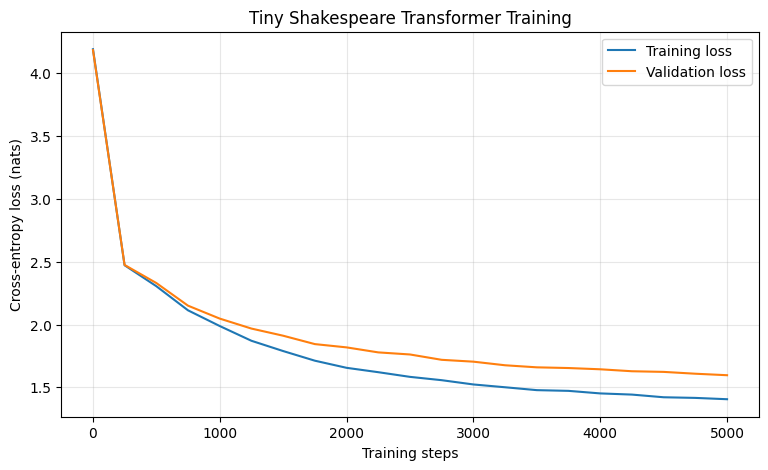


TEMPERATURE: 0.2
ROMEO:
The man, and the country of the company.

DUKE VINCENTIO:
And the common of the sent of the company.

POLIXENES:
I will the sent of his face, which he should be thee,
And the manner of the lords of the marry of the come
To seem the prince of the comes of the death,
And the comes of the shall of the strength of my death,
And so shall be so stand the comes of the rest
That is the comes and the subjects of the prove
That the manner of the father of the more of my love,
And with his part of the com

TEMPERATURE: 0.8
ROMEO:
Caius a destand my moany lord, you we kills that
A sight neck of my seen. The consent affire:
Have shall be come as sorrow time that one such my
Which thee busing as made the equite of a grief!
My noisely, what we said may with his patient.

BUCKINGHAM:
Let me the king.

FRIAR LAURENCE EDWARD:
The confent
That ranother's hopest: must be kings as these in't.

COMINIUS:
A dissides, from what we marry.

LUCIO:
Now if not not brother holy, for will n

In [ ]:

import os
import time
import math
import copy
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

# =========================
# CONFIGURATION
# =========================

SEED = 42
D = 128
LAYERS = 4
HEADS = 4
CONTEXT = 128
DROPOUT = 0.1
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
MAX_STEPS = 5000
EVAL_INTERVAL = 250
EVAL_BATCHES = 30

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.makedirs("figures", exist_ok=True)
os.makedirs("generated", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Device:", DEVICE)


# =========================
# DOWNLOAD TINY SHAKESPEARE
# =========================

DATA_PATH = Path("tiny_shakespeare.txt")

if not DATA_PATH.exists():
    url = (
        "https://raw.githubusercontent.com/"
        "karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    )
    urllib.request.urlretrieve(url, DATA_PATH)

text = DATA_PATH.read_text(encoding="utf-8")

chars = sorted(list(set(text)))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)

split = int(0.90 * len(data))

train_data = data[:split]
val_data = data[split:]

print("Total characters:", len(text))
print("Vocabulary size:", vocab_size)
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

assert vocab_size == 65, (
    f"Expected approximately 65 characters, got {vocab_size}"
)

# =========================
# BATCH GENERATION
# =========================

def get_batch(split_name, context_length=CONTEXT):
    source = train_data if split_name == "train" else val_data

    ix = torch.randint(
        len(source) - context_length - 1,
        (BATCH_SIZE,)
    )

    x = torch.stack([
        source[i:i + context_length] for i in ix
    ])

    y = torch.stack([
        source[i + 1:i + context_length + 1] for i in ix
    ])

    return x.to(DEVICE), y.to(DEVICE)

# =========================
# SELF ATTENTION
# =========================

class SelfAttention(nn.Module):

    def __init__(self, d, heads, dropout=0.1, causal=True):
        super().__init__()

        assert d % heads == 0

        self.d = d
        self.heads = heads
        self.head_dim = d // heads
        self.causal = causal

        self.W_Q = nn.Linear(d, d)
        self.W_K = nn.Linear(d, d)
        self.W_V = nn.Linear(d, d)
        self.W_O = nn.Linear(d, d)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):

        B, T, C = x.shape

        Q = self.W_Q(x)
        K = self.W_K(x)
        V = self.W_V(x)

        # Split into heads
        Q = Q.view(B, T, self.heads, self.head_dim).transpose(1, 2)
        K = K.view(B, T, self.heads, self.head_dim).transpose(1, 2)
        V = V.view(B, T, self.heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        scores = Q @ K.transpose(-2, -1)
        scores = scores / math.sqrt(self.head_dim)

        if self.causal:
            mask = torch.tril(
                torch.ones(T, T, device=x.device, dtype=torch.bool)
            )
            scores = scores.masked_fill(
                ~mask[None, None, :, :],
                float("-inf")
            )

        weights = F.softmax(scores, dim=-1)

        output = self.dropout(weights) @ V

        output = output.transpose(1, 2).contiguous()
        output = output.view(B, T, C)

        output = self.W_O(output)

        if return_attention:
            return output, weights

        return output


# =========================
# FEED FORWARD NETWORK
# =========================

class FeedForward(nn.Module):

    def __init__(self, d, dropout=0.1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(d, 4 * d),
            nn.GELU(),
            nn.Linear(4 * d, d),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


# =========================
# ENCODER BLOCK
# =========================

class EncoderBlock(nn.Module):

    def __init__(self, d, heads, dropout=0.1, causal=True):
        super().__init__()

        self.ln1 = nn.LayerNorm(d)
        self.attention = SelfAttention(
            d, heads, dropout, causal
        )

        self.ln2 = nn.LayerNorm(d)
        self.ffn = FeedForward(d, dropout)

    def forward(self, x, return_attention=False):

        if return_attention:
            attn_out, weights = self.attention(
                self.ln1(x),
                return_attention=True
            )
        else:
            attn_out = self.attention(self.ln1(x))

        x = x + attn_out
        x = x + self.ffn(self.ln2(x))

        if return_attention:
            return x, weights

        return x


# =========================
# CHARACTER TRANSFORMER
# =========================

class CharacterTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        d=128,
        heads=4,
        layers=4,
        context=128,
        dropout=0.1,
        causal=True
    ):
        super().__init__()

        self.context = context
        self.d = d
        self.heads = heads
        self.causal = causal

        self.token_embedding = nn.Embedding(vocab_size, d)

        self.position_embedding = nn.Embedding(context, d)

        self.blocks = nn.ModuleList([
            EncoderBlock(d, heads, dropout, causal)
            for _ in range(layers)
        ])

        self.final_norm = nn.LayerNorm(d)

        self.lm_head = nn.Linear(d, vocab_size)

    def forward(self, idx, return_attention=False):

        B, T = idx.shape

        assert T <= self.context

        positions = torch.arange(T, device=idx.device)

        x = (
            self.token_embedding(idx)
            + self.position_embedding(positions)[None, :, :]
        )

        attention_weights = None

        for i, block in enumerate(self.blocks):

            if return_attention and i == len(self.blocks) - 1:
                x, attention_weights = block(
                    x, return_attention=True
                )
            else:
                x = block(x)

        x = self.final_norm(x)

        logits = self.lm_head(x)

        if return_attention:
            return logits, attention_weights

        return logits


print("Transformer classes defined.")

# =========================
# EVALUATION
# =========================

@torch.no_grad()
def estimate_loss(model):

    model.eval()

    results = {}

    for split_name in ["train", "val"]:

        losses = []

        for _ in range(EVAL_BATCHES):

            x, y = get_batch(split_name, model.context)

            logits = model(x)

            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                y.reshape(-1)
            )

            losses.append(loss.item())

        results[split_name] = float(np.mean(losses))

    model.train()

    return results


# =========================
# TRAINING
# =========================

def train_model(
    model,
    max_steps=MAX_STEPS,
    eval_interval=EVAL_INTERVAL,
    verbose=True
):

    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.01
    )

    history = []

    start = time.perf_counter()

    for step in range(1, max_steps + 1):

        model.train()

        x, y = get_batch("train", model.context)

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()

        if step % eval_interval == 0 or step == 1:

            metrics = estimate_loss(model)

            history.append({
                "step": step,
                "train_loss": metrics["train"],
                "val_loss": metrics["val"]
            })

            if verbose:
                print(
                    f"Step {step:5d} | "
                    f"Train: {metrics['train']:.4f} | "
                    f"Val: {metrics['val']:.4f} | "
                    f"BPC: {metrics['val']/math.log(2):.4f}"
                )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - start

    final_metrics = estimate_loss(model)

    final_loss = final_metrics["val"]
    bpc = final_loss / math.log(2)

    print("\nTraining completed")
    print("Validation loss:", round(final_loss, 4), "nats")
    print("Bits per character:", round(bpc, 4))
    print("Total training time:", round(total_time, 2), "seconds")

    return model, history, {
        "val_loss": final_loss,
        "bpc": bpc,
        "training_time": total_time,
        "parameters": sum(p.numel() for p in model.parameters())
    }


# =========================
# TRAIN MAIN MODEL
# =========================

main_model = CharacterTransformer(
    vocab_size=vocab_size,
    d=D,
    heads=HEADS,
    layers=LAYERS,
    context=CONTEXT,
    dropout=DROPOUT,
    causal=True
)

print(
    "Parameters:",
    sum(p.numel() for p in main_model.parameters())
)

main_model, history, main_results = train_model(main_model)

pd.DataFrame(history).to_csv(
    "results/task4_training_history.csv",
    index=False
)

pd.DataFrame([main_results]).to_csv(
    "results/task4_main_results.csv",
    index=False
)

# =========================
# TRAINING CURVE
# =========================

history_df = pd.DataFrame(history)

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["step"],
    history_df["train_loss"],
    label="Training loss"
)

plt.plot(
    history_df["step"],
    history_df["val_loss"],
    label="Validation loss"
)

plt.xlabel("Training steps")
plt.ylabel("Cross-entropy loss (nats)")
plt.title("Tiny Shakespeare Transformer Training")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "figures/task4_training_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# =========================
# TOP-K GENERATION
# =========================

@torch.no_grad()
def generate(
    model,
    start_text="ROMEO:",
    max_new_tokens=500,
    temperature=0.8,
    top_k=20
):

    model.eval()

    start = torch.tensor(
        [encode(start_text)],
        dtype=torch.long,
        device=DEVICE
    )

    idx = start

    for _ in range(max_new_tokens):

        idx_cond = idx[:, -model.context:]

        logits = model(idx_cond)

        logits = logits[:, -1, :]

        logits = logits / temperature

        if top_k is not None:
            k = min(top_k, logits.size(-1))

            values, _ = torch.topk(logits, k)

            threshold = values[:, [-1]]

            logits = logits.masked_fill(
                logits < threshold,
                float("-inf")
            )

        probs = F.softmax(logits, dim=-1)

        next_char = torch.multinomial(probs, num_samples=1)

        idx = torch.cat((idx, next_char), dim=1)

    model.train()

    return decode(idx[0].tolist())


# =========================
# GENERATE AT THREE TEMPERATURES
# =========================

generation_results = []

for temperature in [0.2, 0.8, 1.5]:

    generated_text = generate(
        main_model,
        start_text="ROMEO:",
        max_new_tokens=500,
        temperature=temperature,
        top_k=20
    )

    filename = f"generated/task4_temp_{temperature}.txt"

    with open(filename, "w", encoding="utf-8") as f:
        f.write(generated_text)

    generation_results.append({
        "temperature": temperature,
        "generated_text": generated_text
    })

    print("\n" + "=" * 70)
    print("TEMPERATURE:", temperature)
    print("=" * 70)
    print(generated_text)

print("Generation completed.")


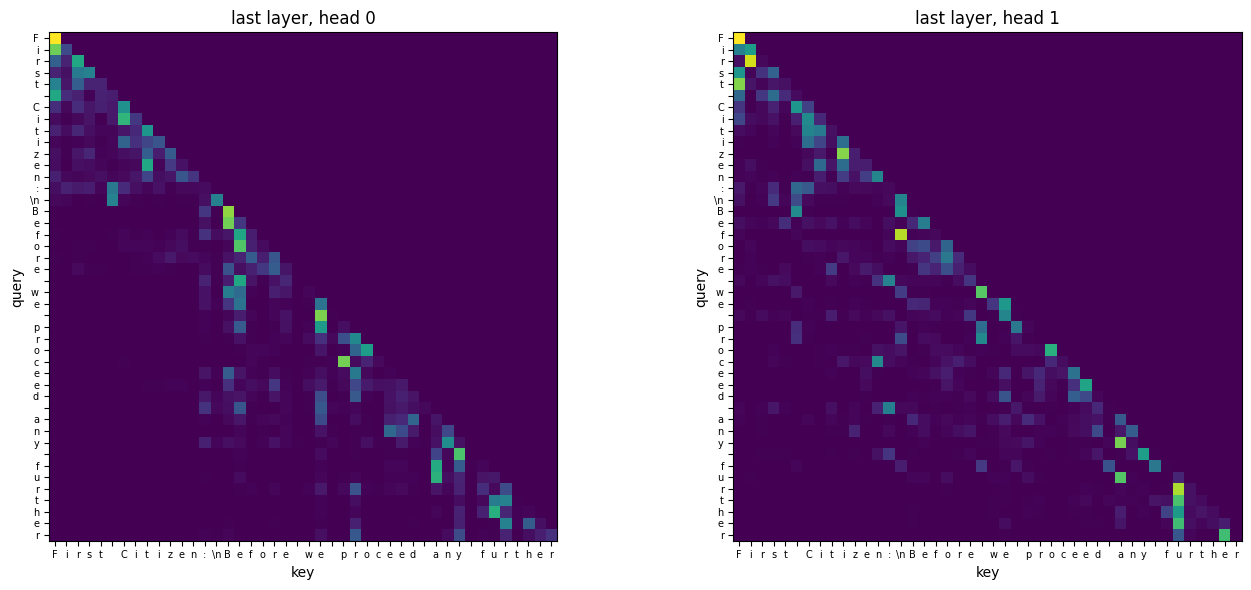


Training completed
Validation loss: 1.7777 nats
Bits per character: 2.5647
Total training time: 52.34 seconds

Training completed
Validation loss: 1.8239 nats
Bits per character: 2.6314
Total training time: 68.15 seconds

Training completed
Validation loss: 1.8428 nats
Bits per character: 2.6586
Total training time: 88.01 seconds
   heads  head_dim  params  val_nats     bpc
0      1       128  826433    1.7777  2.5647
1      4        32  826433    1.8239  2.6314
2      8        16  826433    1.8428  2.6586


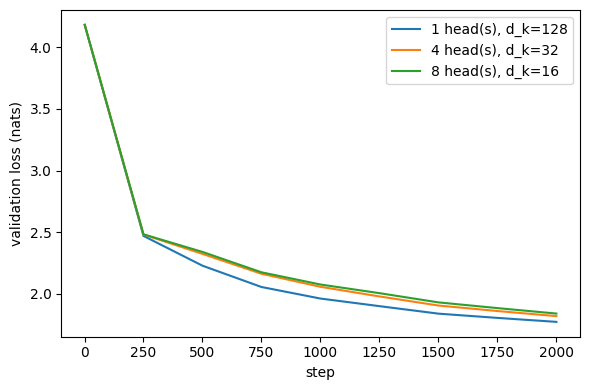


Training completed
Validation loss: 0.0203 nats
Bits per character: 0.0292
Total training time: 64.09 seconds
no mask: train/val (unmasked) = 0.019 / 0.020; val with causal mask at inference = 6.025


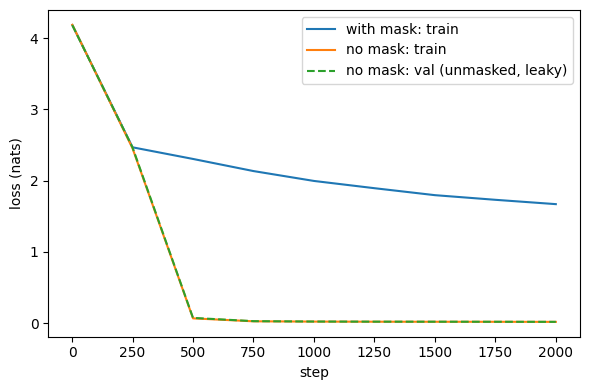

ROMEO:;;EE;;EEEEEEE?EEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEE
   ctx  ms_per_step  peak_MB
0   64        10.64    78.42
1  128        10.60   126.06
2  256        19.01   259.74
3  512        53.27   704.49
log-log slope (time): 0.78


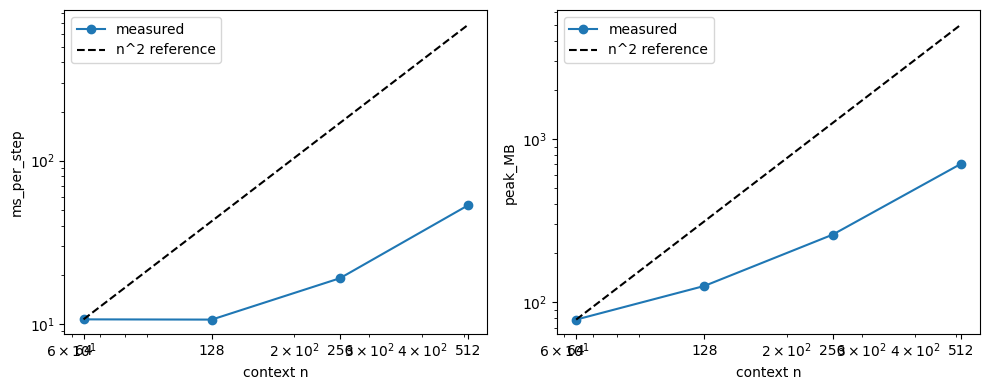

In [ ]:
# ===== Task B outputs + Task 5 (uses CharacterTransformer, train_model, get_batch from Task B) =====
import pandas as pd, numpy as np, torch, math, time
import matplotlib.pyplot as plt

RESULTS_CSV = "../results.csv"
COLS = ["problem","model","seed","seq_len","test_acc","macro_f1","test_mse","params",
        "sec_per_epoch","val_loss_nats","bits_per_char","notes"]
def log_row(**kw):
    pd.DataFrame([{c: kw.get(c, "") for c in COLS}]).to_csv(
        RESULTS_CSV, mode="a", index=False, header=not os.path.exists(RESULTS_CSV))

# --- generated_samples.txt (the three labelled samples) + results row ---
with open("generated_samples.txt", "w", encoding="utf-8") as f:
    for r in generation_results:
        f.write(f"=== temperature {r['temperature']} (top-k 20, 500 new characters) ===\n{r['generated_text']}\n\n")
log_row(problem="P2_LM", model="CharLM-h4", seed=SEED, seq_len=CONTEXT,
        params=main_results["parameters"], sec_per_epoch=main_results["training_time"] / (5000 * BATCH_SIZE * CONTEXT / len(train_data)),
        val_loss_nats=main_results["val_loss"], bits_per_char=main_results["bpc"],
        notes=f"d={D},layers={LAYERS},heads=4,ctx={CONTEXT},steps=5000,device={DEVICE}")

# --- 5(a): heatmaps, two heads of the last layer on one sentence ---
sentence = "First Citizen:\nBefore we proceed any further"
idx = torch.tensor([encode(sentence)], device=DEVICE)
main_model.eval()
with torch.no_grad():
    _, attn = main_model(idx, return_attention=True)          # (1, H, T, T), last layer
labels = [c if c != "\n" else "\\n" for c in sentence]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, h in zip(axes, (0, 1)):                                # pick two heads that look different
    ax.imshow(attn[0, h].cpu().numpy(), cmap="viridis")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=7)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlabel("key"); ax.set_ylabel("query"); ax.set_title(f"last layer, head {h}")
plt.tight_layout(); plt.savefig("figures/attention_heatmaps.png", dpi=200); plt.show()

# --- 5(b): heads 1, 4, 8 at fixed d, same shorter budget ---
ABL_STEPS = 2000
head_res = {}
for h in (1, 4, 8):
    torch.manual_seed(0)
    m = CharacterTransformer(vocab_size, d=D, heads=h, layers=LAYERS, context=CONTEXT, dropout=DROPOUT, causal=True)
    _, hist, res = train_model(m, max_steps=ABL_STEPS, verbose=False)
    head_res[h] = (hist, res)
    log_row(problem="P2_LM", model=f"CharLM-h{h}-abl", seed=0, seq_len=CONTEXT, params=res["parameters"],
            val_loss_nats=res["val_loss"], bits_per_char=res["bpc"], notes=f"steps={ABL_STEPS}")
print(pd.DataFrame([dict(heads=h, head_dim=D // h, params=r["parameters"], val_nats=round(r["val_loss"], 4),
                         bpc=round(r["bpc"], 4)) for h, (_, r) in head_res.items()]))
plt.figure(figsize=(6, 4))
for h, (hist, _) in head_res.items():
    d_ = pd.DataFrame(hist); plt.plot(d_.step, d_.val_loss, label=f"{h} head(s), d_k={D // h}")
plt.xlabel("step"); plt.ylabel("validation loss (nats)"); plt.legend(); plt.tight_layout()
plt.savefig("figures/heads_ablation.png", dpi=200); plt.show()

# --- 5(c): no causal mask ---
torch.manual_seed(0)
nm = CharacterTransformer(vocab_size, d=D, heads=4, layers=LAYERS, context=CONTEXT, dropout=DROPOUT, causal=False)
nm, hist_nm, res_nm = train_model(nm, max_steps=ABL_STEPS, verbose=False)
leaky_val = res_nm["val_loss"]                                  # evaluated WITHOUT mask (sees the answer)
for b in nm.blocks: b.attention.causal = True                   # honest inference setting
honest_val = estimate_loss(nm)["val"]
log_row(problem="P2_LM", model="CharLM-h4-nomask", seed=0, seq_len=CONTEXT, params=res_nm["parameters"],
        val_loss_nats=honest_val, bits_per_char=honest_val / math.log(2),
        notes=f"steps={ABL_STEPS},val_without_mask={leaky_val:.4f}")
print(f"no mask: train/val (unmasked) = {pd.DataFrame(hist_nm).train_loss.iloc[-1]:.3f} / {leaky_val:.3f}; "
      f"val with causal mask at inference = {honest_val:.3f}")
base = pd.DataFrame(head_res[4][0]); nmh = pd.DataFrame(hist_nm)
plt.figure(figsize=(6, 4))
plt.plot(base.step, base.train_loss, label="with mask: train"); plt.plot(nmh.step, nmh.train_loss, label="no mask: train")
plt.plot(nmh.step, nmh.val_loss, "--", label="no mask: val (unmasked, leaky)")
plt.xlabel("step"); plt.ylabel("loss (nats)"); plt.legend(); plt.tight_layout()
plt.savefig("figures/no_mask.png", dpi=200); plt.show()
with open("no_mask_sample.txt", "w", encoding="utf-8") as f:
    f.write(generate(nm, "ROMEO:", 500, 0.8, 20))
print(open("no_mask_sample.txt").read()[:300])

# --- 5(d): time and memory vs context length ---
rows = []
for ctx in (64, 128, 256, 512):
    m = CharacterTransformer(vocab_size, d=D, heads=4, layers=LAYERS, context=ctx, dropout=0.0).to(DEVICE).train()
    x = torch.randint(0, vocab_size, (16, ctx), device=DEVICE)
    def step():
        m.zero_grad(set_to_none=True)
        F.cross_entropy(m(x).reshape(-1, vocab_size), x.reshape(-1)).backward()
    if DEVICE.type == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    for _ in range(3): step()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(10): step()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    rows.append(dict(ctx=ctx, ms_per_step=(time.time() - t0) / 10 * 1000,
                     peak_MB=torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else float("nan")))
    del m, x
sc = pd.DataFrame(rows); print(sc.round(2)); sc.to_csv("scaling.csv", index=False)
print("log-log slope (time):", round(np.polyfit(np.log(sc.ctx), np.log(sc.ms_per_step), 1)[0], 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, col in zip(ax, ("ms_per_step", "peak_MB")):
    a.loglog(sc.ctx, sc[col], "o-", label="measured")
    a.loglog(sc.ctx, sc[col].iloc[0] * (sc.ctx / 64) ** 2, "k--", label="n^2 reference")
    a.set_xticks(sc.ctx); a.set_xticklabels(sc.ctx); a.set_xlabel("context n"); a.set_ylabel(col); a.legend()
plt.tight_layout(); plt.savefig("figures/scaling.png", dpi=200); plt.show()